In [3]:
import math
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# ДЗ 1. Масштабування IaaS-віртуальних машин

Виконав: Олег Басистий

## Постановка задачі

### Опис проблеми

Хмарний сервіс обробляє потік запитів інтенсивністю $\lambda$ (запитів/хв). Запити обслуговуються набором однакових віртуальних машин, розгорнутих на одному фізичному хості. Якщо VM замало, сервіс перевантажується. Якщо забагато -- маємо переплату за оренду та ризик вичерпати ресурси хоста.

### Стейкхолдер

Власник IaaS-сервісу, що платить за активні VM, а також відповідає за якість обслуговування.

### Мета дослідження

Для кожного з трьох сценаріїв навантаження ($\lambda = 600,\ 720,\ 900$ запитів/хв) знайти найменшу за вартістю кількість VM, яка:
- забезпечує запас продуктивності (завантаження не вище 75 %);
- вміщується в ресурси фізичного хоста (vCPU та RAM).

### KPI

Місячна вартість $C(n)$, дол./міс., має бути якнайменшою.

## Математична модель

### Змінна рішення

$n$ -- кількість активних VM, шт.; ціле, $n \in \{2, 3, \dots, 12\}$ (11 кандидатних планів).

### Параметри

- $\mu = 120$ запитів/хв -- продуктивність однієї VM
- $c_{cpu} = 2$ vCPU -- кількість vCPU, яку займає одна VM
- $c_{ram} = 4$ GB -- обсяг RAM, який використовує одна VM
- $CPU_{max} = 32$ vCPU -- максимальна кількість vCPU хоста, доступна для VM
- $RAM_{max} = 64$ GB -- максимальний обсяг RAM хоста, доступний для VM
- $p = 0{,}18$ дол./год -- тариф за одну VM
- $H = 720$ год/міс. -- кількість годин роботи у місяці
- $\rho_{max} = 0{,}75$ -- максимально допустиме завантаження VM (запас продуктивності 25 %).
### Фактори

#### Керований фактор 
$n$ -- кількість активних VM, шт.; ціле, $n \in \{2, \dots, 12\}$. Це рішення власника сервісу.

#### Некерований фактор
 $\lambda$ -- інтенсивність вхідного потоку запитів, запитів/хв. Власник сервісу на неї не впливає, тому її задано трьома сценаріями: $\lambda = 600;\ 720;\ 900$. Вона входить у формулу завантаження $\rho$.

#### Фіксовані (зовнішні) параметри
 $\mu,\ c_{cpu},\ c_{ram},\ CPU_{max},\ RAM_{max},\ p,\ H,\ \rho_{max}$ (значення й одиниці див. у п. 2.2). Це конфігурація VM, ресурси хоста, тариф і поріг завантаження. Їх задає провайдер, обладнання або вимога до запасу продуктивності, і в межах задачі вони не змінюються.


### Математичні залежності

Місячна вартість (KPI):
$$C(n) = p \cdot H \cdot n = 0{,}18 \cdot 720 \cdot n = 129{,}6\,n \quad \text{дол./міс.}$$

Коефіцієнт завантаження пулу VM:
$$\rho(n, \lambda) = \frac{\lambda}{\mu\, n} = \frac{\lambda}{120\, n}$$

Використання ресурсів хоста:
$$CPU(n) = c_{cpu}\, n = 2n, \qquad RAM(n) = c_{ram}\, n = 4n$$

### Оптимізаційна задача


Цільова функція. 
Мінімізуємо місячну вартість, дол./міс.:

$$\min_{n} \; C(n) = 129{,}6\, n$$

Обмеження:

- запас продуктивності: $\rho = \dfrac{\lambda}{\mu n} = \dfrac{\lambda}{120 n} \le \rho_{max} = 0{,}75$;
- vCPU хоста: $c_{cpu} n = 2n \le CPU_{max} = 32$ vCPU;
- RAM хоста: $c_{ram} n = 4n \le RAM_{max} = 64$ GB.

Область значень: $n \in \{2, \dots, 12\},\ n \in \mathbb{Z}$, тобто допустимі лише цілі значення $n$.

Оскільки $C(n)$ строго зростає за $n$, оптимальне значення $n$ -- найменше допустиме. З обмеження за $\rho$ випливає $n \ge \lambda / (0{,}75 \cdot 120) = \lambda / 90$, тобто $n^* = \max(2, \lceil \lambda/90 \rceil)$, якщо воно не порушує ліміти хоста. Цей результат використаємо для перевірки перебору.



### 2.6 Припущення моделі

1. Продуктивність пулу зростає лінійно з кількістю VM і дорівнює $\mu n = 120n$ запитів/хв: балансувальник рівномірно розподіляє запити, а накладних витрат на координацію між VM немає.
2. Інтенсивність потоку $\lambda$ у межах сценарію стала й дорівнює найбільшоум розрахунковому значенню. Короткочасні сплески та добові коливання не моделюються.
3. Усі VM однакові й оплачуються за фіксованим погодинним тарифом $p$ протягом усіх $H = 720$ год місяця; простої та знижки не враховуються.
4. Усі VM розміщені на *одному фізичному хості, і його 32 vCPU та 64 GB RAM повністю доступні сервісу.
5. Завантаження $\rho \le 0{,}75$ вважається достатнім запасом продуктивності, тому черги й час відгуку окремо не моделюються.

## 3. Реалізація моделі

In [4]:
MU = 120
VM_CPU = 2
VM_RAM = 4
HOST_CPU = 32
HOST_RAM = 64
PRICE = 0.18
HOURS = 720
RHO_MAX = 0.75

In [5]:
N_CANDIDATES = range(2, 13)
SCENARIOS = [600, 720, 900]

In [7]:
from itertools import product

simulation_data = {
    "lam": [],
    "n": [],
    "rho": [],
    "vcpu": [],
    "ram": [],
    "cost": [],
    "rho_violated": [],
    "cpu_violated": [],
    "ram_violated": [],
}

for lam, n in product(SCENARIOS, N_CANDIDATES):
    rho = lam / (MU * n)
    cpu_used = VM_CPU * n
    ram_used = VM_RAM * n
    cost = PRICE * HOURS * n

    simulation_data["lam"].append(lam)
    simulation_data["n"].append(n)
    simulation_data["rho"].append(round(rho, 4))
    simulation_data["vcpu"].append(cpu_used)
    simulation_data["ram"].append(ram_used)
    simulation_data["cost"].append(round(cost, 2))

    simulation_data["rho_violated"].append(rho > RHO_MAX + 1e-9)
    simulation_data["cpu_violated"].append(cpu_used > HOST_CPU)
    simulation_data["ram_violated"].append(ram_used > HOST_RAM)

all_plans = pd.DataFrame(simulation_data)
all_plans["feasible"] = ~(all_plans["rho_violated"] | all_plans["cpu_violated"] | all_plans["ram_violated"])

In [8]:

display(all_plans)

,lam,n,rho,vcpu,ram,cost,rho_violated,cpu_violated,ram_violated,feasible
0,600,2,2.5000,4,8,259.2,True,False,False,False
1,600,3,1.6667,6,12,388.8,True,False,False,False
2,600,4,1.2500,8,16,518.4,True,False,False,False
3,600,5,1.0000,10,20,648.0,True,False,False,False
4,600,6,0.8333,12,24,777.6,True,False,False,False
5,600,7,0.7143,14,28,907.2,False,False,False,True
6,600,8,0.6250,16,32,1036.8,False,False,False,True
7,600,9,0.5556,18,36,1166.4,False,False,False,True
8,600,10,0.5000,20,40,1296.0,False,False,False,True
9,600,11,0.4545,22,44,1425.6,False,False,False,True


 Зі зростанням $\lambda$ межа допустимості зсувається вправо, перший допустимий план має $n = 7$, $8$ і $10$ відповідно.  
 
 Усі недопустимі плани відсіяні лише за $\rho$, а ліміти хоста не порушено жодного разу.   
 
 Оскільки $\rho \sim 1/n$, кожна додаткова VM знижує завантаження ще менше за ту саму ціну, тому кількість VM > $n^*$ майже нічого не дають.


In [11]:
summary_data = {
    "lam": [],
    "n_opt": [],
    "rho": [],
    "vcpu": [],
    "ram": [],
    "cost": [],
    "n_feasible": [],
}

for lam in SCENARIOS:
    feasible = all_plans[(all_plans["lam"] == lam) & all_plans["feasible"]]
    best = feasible.loc[feasible["cost"].idxmin()]

    summary_data["lam"].append(lam)
    summary_data["n_opt"].append(int(best["n"]))
    summary_data["rho"].append(best["rho"])
    summary_data["vcpu"].append(int(best["vcpu"]))
    summary_data["ram"].append(int(best["ram"]))
    summary_data["cost"].append(best["cost"])
    summary_data["n_feasible"].append(len(feasible))

summary = pd.DataFrame(summary_data)
summary

,lam,n_opt,rho,vcpu,ram,cost,n_feasible
0,600,7,0.7143,14,28,907.2,6
1,720,8,0.7500,16,32,1036.8,5
2,900,10,0.7500,20,40,1296.0,3


Оптимальна кількість VM зростає разом із навантаженням.  

При $\lambda = 720$ і $900$ оптимум лежить рівно на межі $\rho = 0,75$. При $\lambda = 600$ округлення $6,67 \to 7$ дає $\rho = 0,714$, тобто невеликий запас, за який доводиться платити.   

Хост при оптимумі зайнятий лише на 44-63 %, тому вузьким місцем він не є.


 Перевіримо, чи хоч раз у діапазоні $n = 2, \dots, 12$ спрацьовують ліміти CPU та RAM:

In [27]:
n_max = max(N_CANDIDATES)
print(f"Max CPU in range: {VM_CPU * n_max} / {HOST_CPU} vCPU \
({HOST_CPU - VM_CPU * n_max} spare)")
print(f"Max RAM in range: {VM_RAM * n_max} / {HOST_RAM} GB \
({HOST_RAM - VM_RAM * n_max} spare)")
print(f"Host can hold up to n = {min(HOST_CPU // VM_CPU, HOST_RAM // VM_RAM)} VM")

print(f"Violations by rho: {all_plans['rho_violated'].sum()}, \
by CPU: {all_plans['cpu_violated'].sum()}, \
by RAM: {all_plans['ram_violated'].sum()} ")

Max CPU in range: 24 / 32 vCPU (8 spare)
Max RAM in range: 48 / 64 GB (16 spare)
Host can hold up to n = 16 VM
Violations by rho: 19, by CPU: 0, by RAM: 0 


Ліміти CPU і RAM у заданому діапазоні неактивні і навіть при $n = 12$ використовується лише 24 з 32 vCPU та 48 з 64 GB.  

Отже, оптимум повністю визначається обмеженням за завантаженням $\rho \le 0{,}75$.

Те, що перевірки CPU і RAM неактивні, не означає, що вони не працюють. Для демонстрації візьмемо план поза множиною рішень, $n = 17$: $2 \cdot 17 = 34 > 32$ vCPU і $4 \cdot 17 = 68 > 64$ GB, тож мають спрацювати обидва ліміти хоста (а за $\rho$ порушення немає):

In [28]:
lam, n = 720, 17
print(f"ρ   = {lam / (MU * n):.3f} > {RHO_MAX}: {lam / (MU * n) > RHO_MAX}")
print(f"CPU = {VM_CPU * n} > {HOST_CPU}: {VM_CPU * n > HOST_CPU}")
print(f"RAM = {VM_RAM * n} > {HOST_RAM}: {VM_RAM * n > HOST_RAM}")

ρ   = 0.353 > 0.75: False
CPU = 34 > 32: True
RAM = 68 > 64: True


## 5. Графік C(n) від n із виділенням допустимих планів

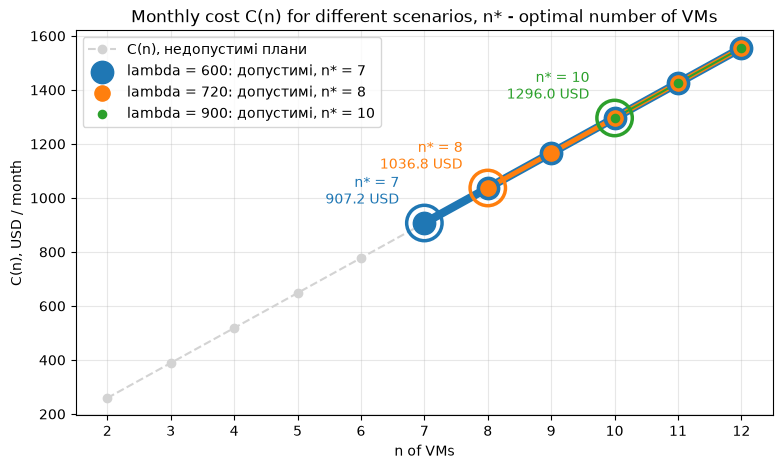

In [ ]:
colors = {600: "tab:blue", 720: "tab:orange", 900: "tab:green"}
widths = {600: 6, 720: 3.5, 900: 1.5}
sizes = {600: 260, 720: 120, 900: 35}

ns = list(N_CANDIDATES)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ns, [PRICE * HOURS * n for n in ns], color="lightgray", ls="--", marker="o",
        markersize=6, label="C(n), недопустимі плани")

for lam in SCENARIOS:
    feasible = all_plans[(all_plans["lam"] == lam) & all_plans["feasible"]]
    n_opt = int(summary.loc[summary["lam"] == lam, "n_opt"].iloc[0])
    ax.plot(feasible["n"], feasible["cost"], color=colors[lam], lw=widths[lam], zorder=2)
    ax.scatter(feasible["n"], feasible["cost"], s=sizes[lam], color=colors[lam], zorder=3,
               label=f"lambda = {lam}: допустимі, n* = {n_opt}")

    # кільце на оптимумі
    cost_opt = PRICE * HOURS * n_opt
    ax.scatter(n_opt, cost_opt, s=650, facecolors="none", edgecolors=colors[lam], linewidths=2.5, zorder=4)
    ax.annotate(f"n* = {n_opt}\n{cost_opt:.1f} USD", (n_opt, cost_opt),
                textcoords="offset points", xytext=(-18, 14), ha="right", color=colors[lam])

ax.set_xticks(ns)
ax.set_xlabel("n of VMs")
ax.set_ylabel("C(n), USD / month")
ax.set_title("Monthly cost C(n) for different scenarios, n* - optimal number of VMs")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Вартість не залежить від $\lambda$, тому три лінії лежать на одній прямій. Щоб їх було видно, вони мають різну товщину. Кожна кольорова лінія починається з оптимального $n^*$, позначеного кільцем із підписаною вартістю.

Усі лінії лежать на прямій $C(n) = 129{,}6\,n$, тобто вартість плану не залежить від $\lambda$. Сценарій навантаження визначає лише, з якого $n$ починаються допустимі плани.  


Оптимум -- ліва точка кожної кольорової лінії. Плани правіше теж допустимі, але кожен крок вправо коштує +129,6 дол./міс. без користі для KPI.  


Різниця між оптимумами -- ціна зростання навантаження: 129,6 дол./міс. між $\lambda = 600$ і $720$ та 259,2 дол./міс. між $\lambda = 720$ і $900$.  


Сіра пунктирна частина ліворуч -- дешевші, але недопустимі плани.

## 6. Перевірка вручну
Перевіримо для \lambda = 720$, $n = 8$

$\rho = \dfrac{720}{120 \cdot 8} = \dfrac{720}{960} = 0{,}75$ ⇒ $0{,}75 \le 0{,}75$ -- виконується.  

CPU: $2 \cdot 8 = 16$ vCPU $\le 32$ -- виконується.  

RAM $4 \cdot 8 = 32$ GB $\le 64$ -- виконується.  

$C(8) = 0{,}18 \cdot 720 \cdot 8 = 129{,}6 \cdot 8 = 1036{,}8$ дол./міс.

Для порівняння, $n = 7$: $\rho = 720/840 \approx 0{,}857 > 0{,}75$ -- недопустимо. Отже, $n = 8$ -- найменший допустимий план, $n^* = 8$.

Звіримо з кодом:

In [39]:
def plan_row(lam, n):
    return all_plans[(all_plans["lam"] == lam) & (all_plans["n"] == n)].iloc[0]

lam, n = 720, 8
manual = {"rho": 0.75, "vcpu": 16, "ram": 32, "cost": 1036.8}
model = plan_row(lam, n)
for k, v in manual.items():
    print(f"{k:16s} by hand = {v:8}, model = {model[k]:8}, correct: {math.isclose(v, model[k])}")
    assert math.isclose(v, model[k])
assert model["feasible"]
assert not plan_row(720, 7)["feasible"]

rho              by hand =     0.75, model =     0.75, correct: True
vcpu             by hand =       16, model =       16, correct: True
ram              by hand =       32, model =       32, correct: True
cost             by hand =   1036.8, model =   1036.8, correct: True


## 8. Висновок 

| λ, запитів/хв | Рекомендоване $n^*$ | $\rho$ | CPU / RAM хоста | $C(n^*)$, дол./міс. |
|---|---|---|---|---|
| 600 | **7** | 0,714 | 14 vCPU / 28 GB | **907,2** |
| 720 | **8** | 0,750 | 16 vCPU / 32 GB | **1036,8** |
| 900 | **10** | 0,750 | 20 vCPU / 40 GB | **1296,0** |


Вартість $C(n) = 129{,}6\,n$ зростає з $n$, тому оптимальний план -- найменше $n$, яке не порушує жодного обмеження.  

Перебір кількості VM $n = 2, \dots, 12$ дав $n^* = 7$, $8$ і $10$ для $\lambda = 600$, $720$ і $900$. Оптимум визначає лише обмеження на $\rho \le 0{,}75$. Ліміти хоста в цьому діапазоні неактивні, і навіть при $n = 12$ зайнято 24 з 32 vCPU і 48 з 64 GB.

Рекомендовано розмістити **n = 10** VM (1296 дол./міс.). Це найменше $n$, допустиме навіть за найгіршого навантаження $\lambda = 900$. Реальний потік заздалегідь невідомий, тому беремо найбільший з оптимумів за сценаріями. Якщо доступне автомасштабування, можна тримати $n^* = \lceil \lambda/90 \rceil$ і заощаджувати до 388,8 дол./міс. у періоди низького навантаження.

Рекомендація діє за припущень, що продуктивність пулу зростає лінійно ($120n$ запитів/хв), а потік сталий і дорівнює сценарному $\lambda$. Модель не враховує сплесків навантаження і не оцінює черги та час відгуку. Поріг $\rho \le 0{,}75$ -- евристичний, а при $\lambda = 720$ і $900$ оптимум лежить рівно на ньому, тож будь-яке зростання потоку зробить план недопустимим.


**GenAI:**  


Генеративний ШІ (Claude, Anthropic) використано для  покращення візуалізацій та графіків, для оформлення таблиць.